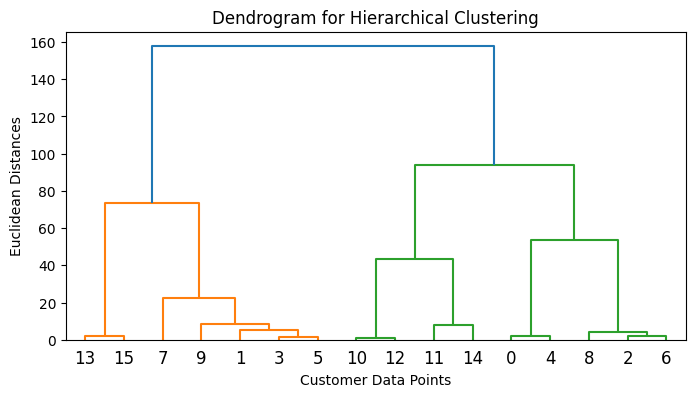

--- CLUSTER ASSIGNMENTS ---
    CustomerID  Annual_Income  Spending_Score  Cluster
0            1             15              39        1
1            2             15              81        0
2            3             16               6        1
3            4             16              77        0
4            5             17              40        1
5            6             17              76        0
6            7             18               6        1
7            8             18              94        0
8            9             19               3        1
9           10             19              72        0
10          11             60              14        2
11          12             60              49        2
12          13             60              15        2
13          14             60              77        0
14          15             61              41        2
15          16             61              79        0


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering

# 1. Load Dataset (Colab upload or Jupyter local file)
# try:
#     from google.colab import files
#     df = pd.read_csv(list(files.upload().keys())[0])
# except ImportError:
df = pd.read_csv(r"/content/customers.csv")

# 2. Select numerical features for clustering [Annual_Income, Spending_Score]
X = df.iloc[:, [3, 4]].values

# 3. Plot Dendrogram to determine optimal number of clusters
plt.figure(figsize=(8, 4))
dendrogram = sch.dendrogram(sch.linkage(X, method='ward'))
plt.title('Dendrogram for Hierarchical Clustering')
plt.xlabel('Customer Data Points')
plt.ylabel('Euclidean Distances')
plt.show()

# 4. Construct Agglomerative Hierarchical Clustering Model
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X)

# 5. Display Clustered Output
df['Cluster'] = y_hc
print("--- CLUSTER ASSIGNMENTS ---")
print(df[['CustomerID', 'Annual_Income', 'Spending_Score', 'Cluster']])

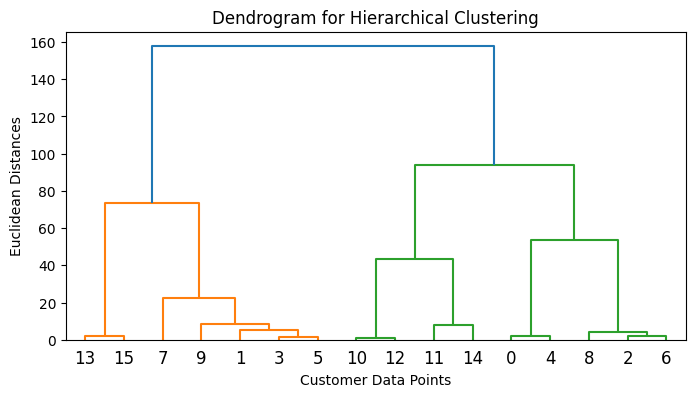

--- CLUSTER ASSIGNMENTS ---
   CustomerID  Annual_Income  Spending_Score  Cluster
0           1             15              39        1
1           2             15              81        0
2           3             16               6        1
3           4             16              77        0
4           5             17              40        1
5           6             17              76        0
6           7             18               6        1
7           8             18              94        0
8           9             19               3        1
9          10             19              72        0


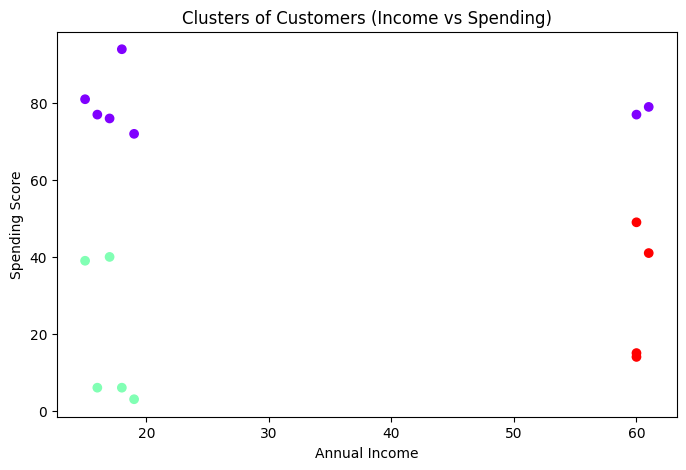

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering


df = pd.read_csv(r"/content/customers.csv")

# 2. Select numerical features for clustering [Annual_Income, Spending_Score]
X = df.iloc[:, [3, 4]].values

# 3. Plot Dendrogram to determine optimal number of clusters
plt.figure(figsize=(8, 4))
dendrogram = sch.dendrogram(sch.linkage(X, method='ward'))
plt.title('Dendrogram for Hierarchical Clustering')
plt.xlabel('Customer Data Points')
plt.ylabel('Euclidean Distances')
plt.show()

# 4. Construct Agglomerative Hierarchical Clustering Model
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X)

# 5. Display Clustered Output
df['Cluster'] = y_hc
print("--- CLUSTER ASSIGNMENTS ---")
print(df[['CustomerID', 'Annual_Income', 'Spending_Score', 'Cluster']].head(10))

# 6. Visualize the Final Clusters (Highly Recommended)
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=y_hc, cmap='rainbow')
plt.title('Clusters of Customers (Income vs Spending)')
plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.show()